실습 설명  
비만도를 나타내는 지표로 'BMI(Body Mass Index)'라는 것도 많이 사용합니다. BMI를 계산하려면 몸무게(kg)를 키(m)의 제곱으로 나눠 주면 되는데요. 예를 들어, 키가 180cm이고, 몸무게가 70kg인 사람의 BMI는 70을 1.8의 제곱으로 나눈 값인 21.6입니다.

위 내용을 참고해서 patient_df에 있는 각 환자의 BMI 값을 계산해서 bmi라는 컬럼에 저장해 주세요. 단, BMI 값은 소수 첫째 자리까지 반올림해 주셔야 합니다.

주의 사항: 채점을 위해 가장 마지막 줄에는 patient_df라고 입력해서 DataFrame을 출력해 주세요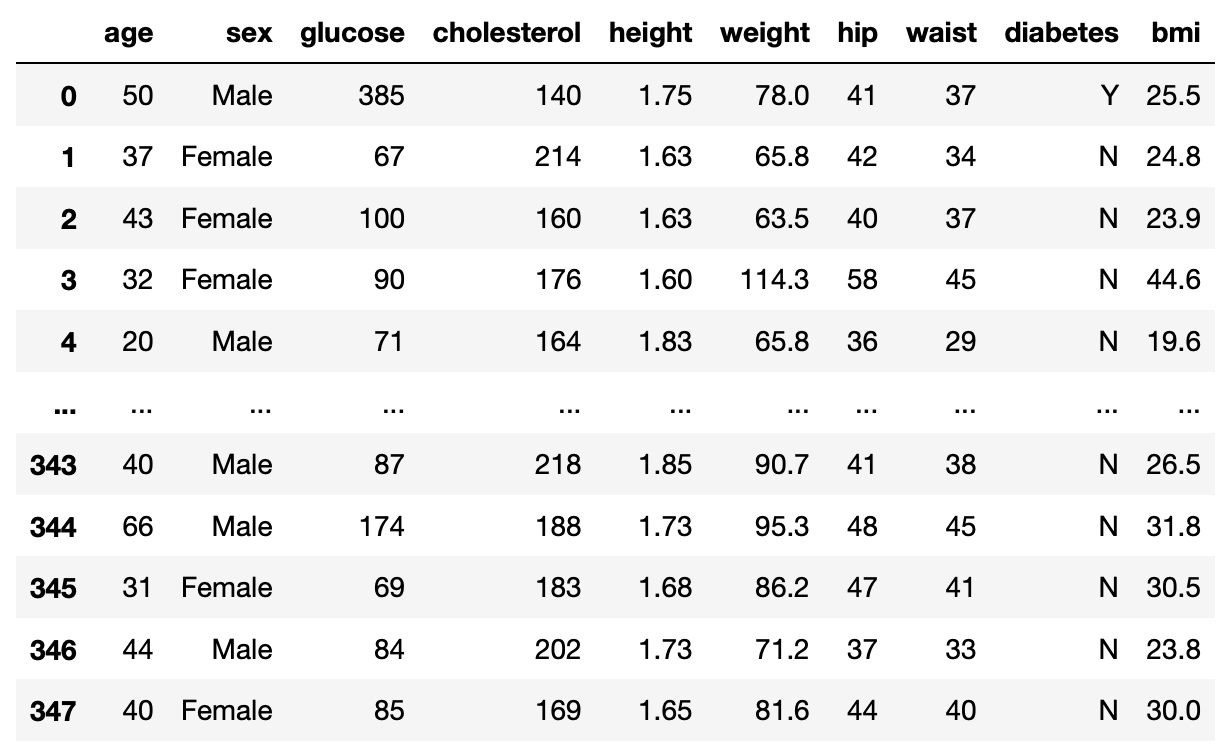

In [17]:
import pandas as pd

patient_df = pd.read_csv('../data/patient.csv')

In [18]:
patient_df['bmi'] = patient_df['weight'] / (patient_df['height'] ** 2)
patient_df['bmi'] = round(patient_df['bmi'],1)
patient_df

,age,sex,glucose,cholesterol,height,weight,hip,waist,diabetes,bmi
0,50,Male,385,140,1.75,78.0,41,37,Y,25.5
1,37,Female,67,214,1.63,65.8,42,34,N,24.8
2,43,Female,100,160,1.63,63.5,40,37,N,23.9
3,32,Female,90,176,1.60,114.3,58,45,N,44.6
4,20,Male,71,164,1.83,65.8,36,29,N,19.6
...,...,...,...,...,...,...,...,...,...,...
343,40,Male,87,218,1.85,90.7,41,38,N,26.5
344,66,Male,174,188,1.73,95.3,48,45,N,31.8
345,31,Female,69,183,1.68,86.2,47,41,N,30.5
346,44,Male,84,202,1.73,71.2,37,33,N,23.8


## 실습 2

실습 설명
weight 컬럼이 0과 1 사이의 값을 가지도록 정규화(Min Max Normalization)를 해 주세요.

주의 사항: 채점을 위해 가장 마지막 줄에는 patient_df라고 입력해서 DataFrame을 출력해 주세요.

In [19]:
patient_df['weight']= (patient_df['weight'] - patient_df['weight'].min()) / \
                      (patient_df['weight'].max() - patient_df['weight'].min())

In [20]:
patient_df

,age,sex,glucose,cholesterol,height,weight,hip,waist,diabetes,bmi
0,50,Male,385,140,1.75,0.322927,41,37,Y,25.5
1,37,Female,67,214,1.63,0.203902,42,34,N,24.8
2,43,Female,100,160,1.63,0.181463,40,37,N,23.9
3,32,Female,90,176,1.60,0.677073,58,45,N,44.6
4,20,Male,71,164,1.83,0.203902,36,29,N,19.6
...,...,...,...,...,...,...,...,...,...,...
343,40,Male,87,218,1.85,0.446829,41,38,N,26.5
344,66,Male,174,188,1.73,0.491707,48,45,N,31.8
345,31,Female,69,183,1.68,0.402927,47,41,N,30.5
346,44,Male,84,202,1.73,0.256585,37,33,N,23.8


In [21]:
patient_df['weight'].describe()

count    348.000000
mean       0.352952
std        0.181349
min        0.000000
25%        0.230244
50%        0.331707
75%        0.446829
max        1.000000
Name: weight, dtype: float64

In [22]:
patient_df['weight'] = (patient_df['weight'] - patient_df['weight'].mean()) / \
    patient_df['weight'].std()

patient_df

,age,sex,glucose,cholesterol,height,weight,hip,waist,diabetes,bmi
0,50,Male,385,140,1.75,-0.165566,41,37,Y,25.5
1,37,Female,67,214,1.63,-0.821892,42,34,N,24.8
2,43,Female,100,160,1.63,-0.945626,40,37,N,23.9
3,32,Female,90,176,1.60,1.787274,58,45,N,44.6
4,20,Male,71,164,1.83,-0.821892,36,29,N,19.6
...,...,...,...,...,...,...,...,...,...,...
343,40,Male,87,218,1.85,0.517659,41,38,N,26.5
344,66,Male,174,188,1.73,0.765127,48,45,N,31.8
345,31,Female,69,183,1.68,0.275572,47,41,N,30.5
346,44,Male,84,202,1.73,-0.531387,37,33,N,23.8


In [23]:
patient_df['weight'].describe()

count    3.480000e+02
mean    -2.909550e-16
std      1.000000e+00
min     -1.946254e+00
25%     -6.766394e-01
50%     -1.171481e-01
75%      5.176593e-01
max      3.567962e+00
Name: weight, dtype: float64

## 실습 설명  
환자들의 비만도를 BMI 값에 따라 분류하려고 합니다. 아래 기준에 따라 비만도를 분류해서 obesity라는 컬럼에 저장해 주세요.

18.5 미만(저체중): under
18.5 이상 25 미만(정상): healthy
25 이상 30 미만(과체중): over
30 이상(비만): obese
주의 사항: 채점을 위해 가장 마지막 줄에는 patient_df라고 입력해서 DataFrame을 출력해 주세요.

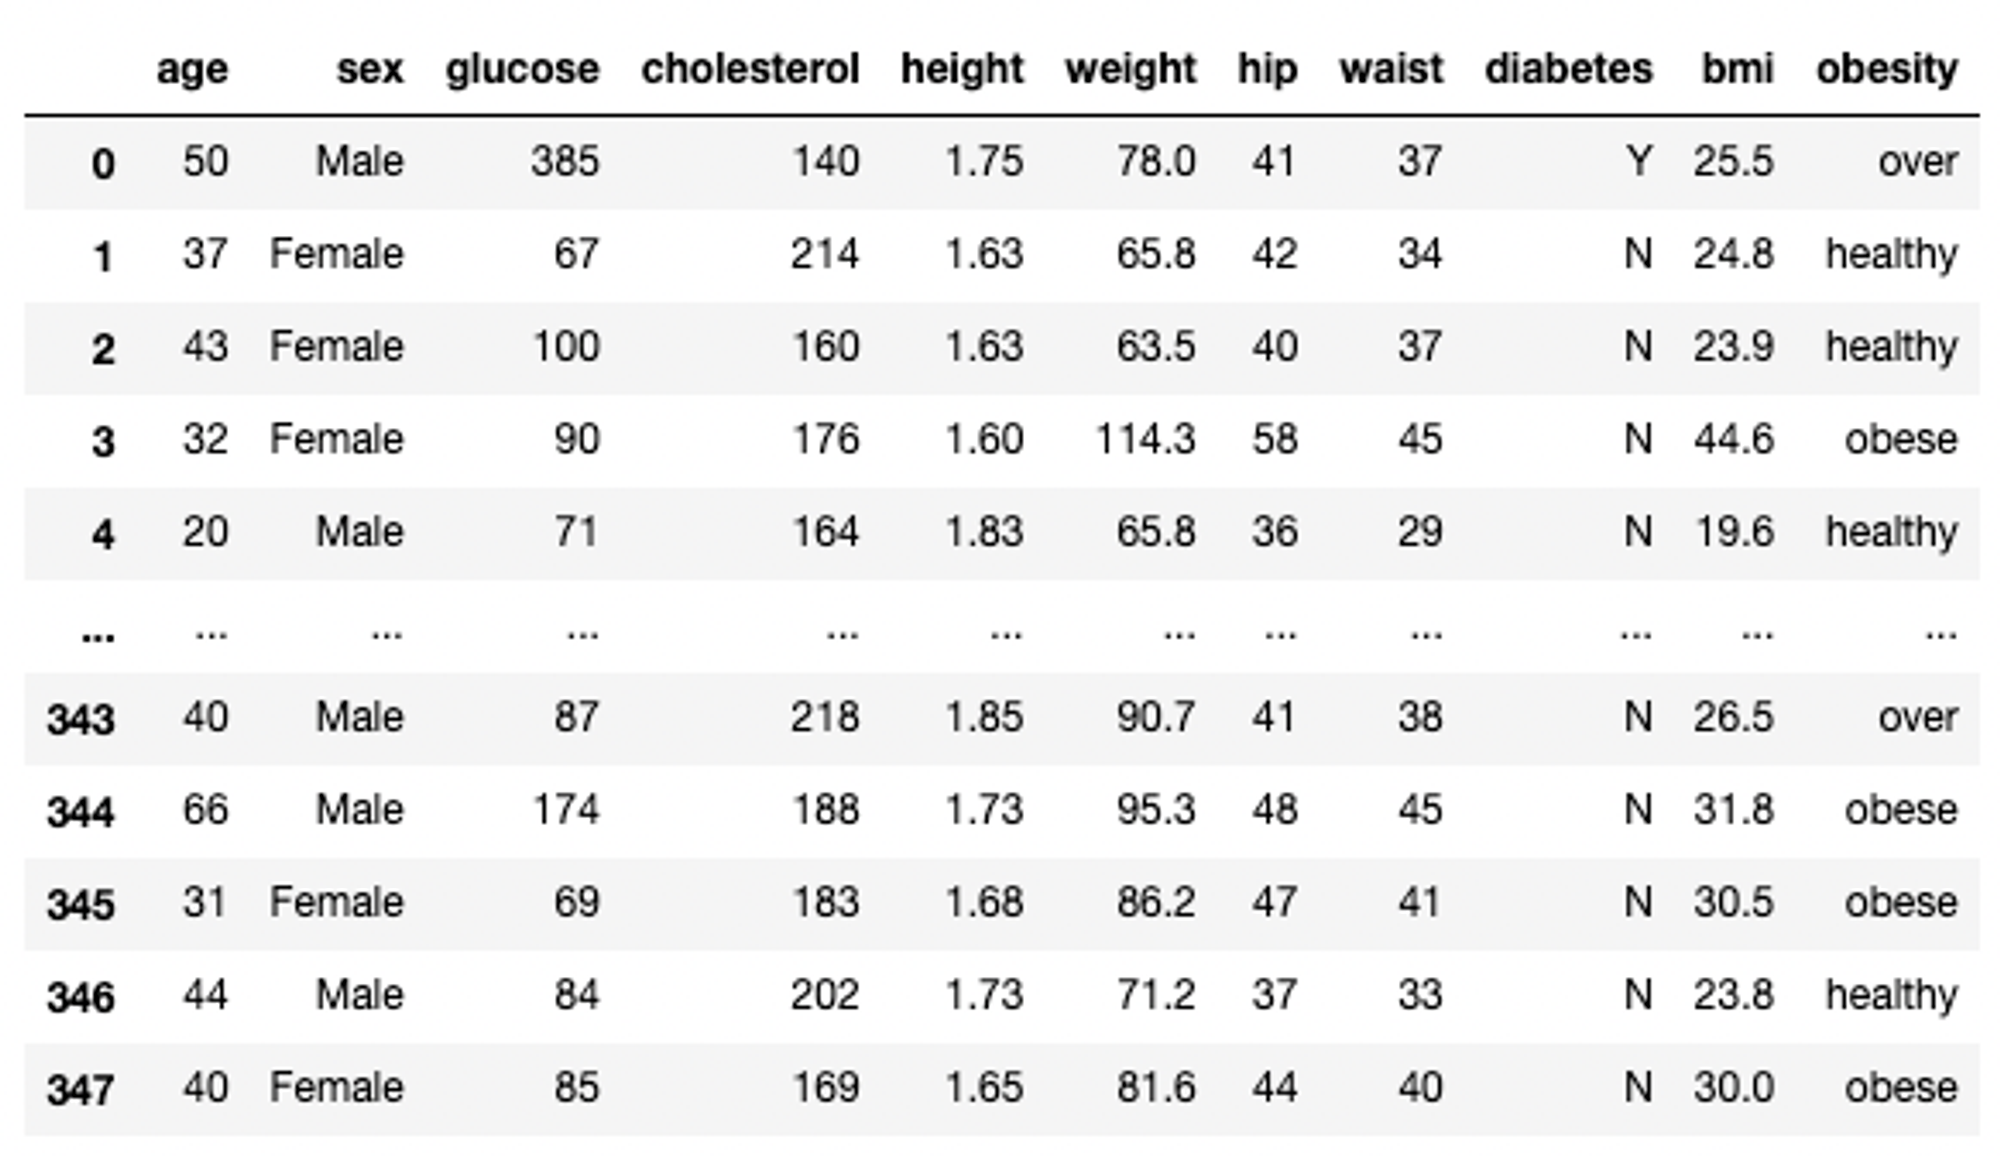

In [24]:
import pandas as pd
import numpy as np

patient_df = pd.read_csv('../data/patient.csv')
patient_df['bmi'] = round(patient_df['weight'] / patient_df['height']**2, 1)

In [25]:
patient_df['bmi'].describe()

count    348.000000
mean      28.839368
std        6.710281
min       15.200000
25%       24.175000
50%       27.800000
75%       32.725000
max       55.500000
Name: bmi, dtype: float64

In [26]:
pd.cut(patient_df['bmi'],
       bins=[10,18.5,25,30,60],
       right=False,
       labels=['under','healthy",'over','dbese'])



SyntaxError: unterminated string literal (detected at line 4) (1813426362.py, line 4)